# 实验4：图像色彩调节

本实验的图片、代码和操作步骤均已包含在本文件夹中。

**运行方式：** 选择本项目的 `.venv` 内核，依次执行单元格，或点击“全部运行”。重新开始时先重启内核。

## 实验目的

理解彩色图像三个通道，进行颜色量化与通道调整，并避免 uint8 溢出。

## 实验原理

颜色量化把相近的像素值映射到同一等级。本实验的量化式为 `floor(v / div) * div + div // 2`。通道增减先转为浮点数，再裁剪到 0–255；直接对 uint8 加法可能发生回绕。本实验使用瓶盖照片观察量化和通道调整的效果。


## 1. 准备环境与路径

算法使用 OpenCV；显示使用 Matplotlib。彩色数组按 BGR 存储，显示前转换成 RGB。图中标题采用英文，说明和练习采用中文，减少系统字体差异。


In [1]:
from pathlib import Path
import sys

# 从 lab 根目录或任意实验子目录启动均可。
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents)
             if (p / "assets" / "manifest.json").is_file()
             and (p / "common" / "io.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("请在 lab 文件夹或其子目录中启动 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from common.io import read_image, save_image, show_images

ASSETS = ROOT / "assets"
OUT = ROOT / "outputs" / "lab04"
OUT.mkdir(parents=True, exist_ok=True)


## 2. 查看 B、G、R 通道

单通道用灰度显示：越亮表示该通道数值越大，并非该区域本身就是白色。


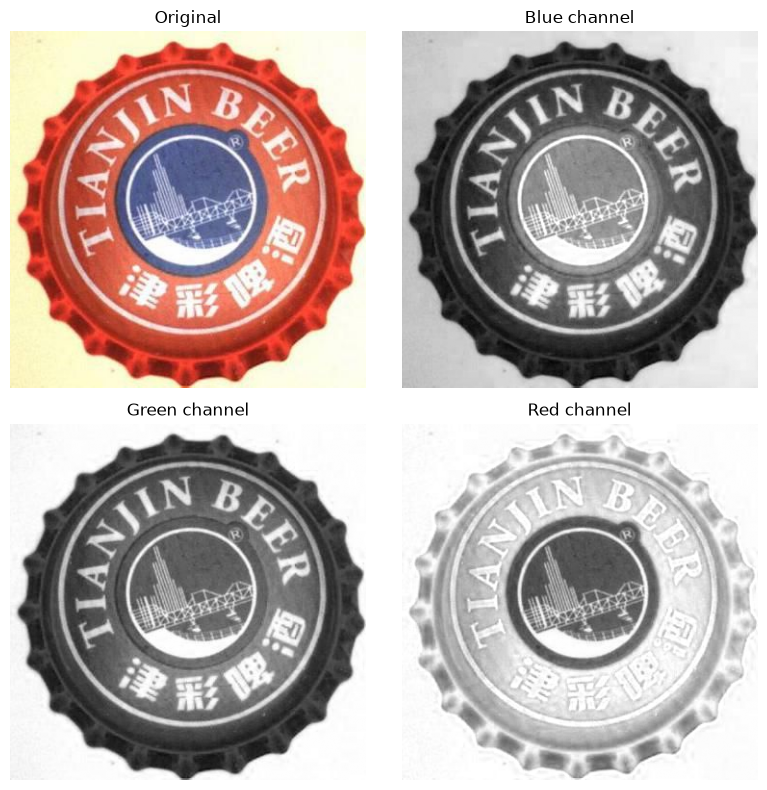

In [2]:
image = read_image(ASSETS / "pdf/bottle_cap.png")
b, g, r = cv2.split(image)
show_images({"Original": image, "Blue channel": b, "Green channel": g, "Red channel": r}, cols=2,
            save_to=OUT / "channels.png")


## 3. 颜色量化

div 越大，可用的像素等级越少。使用 uint16 中间结果避免溢出，最后转回 uint8。


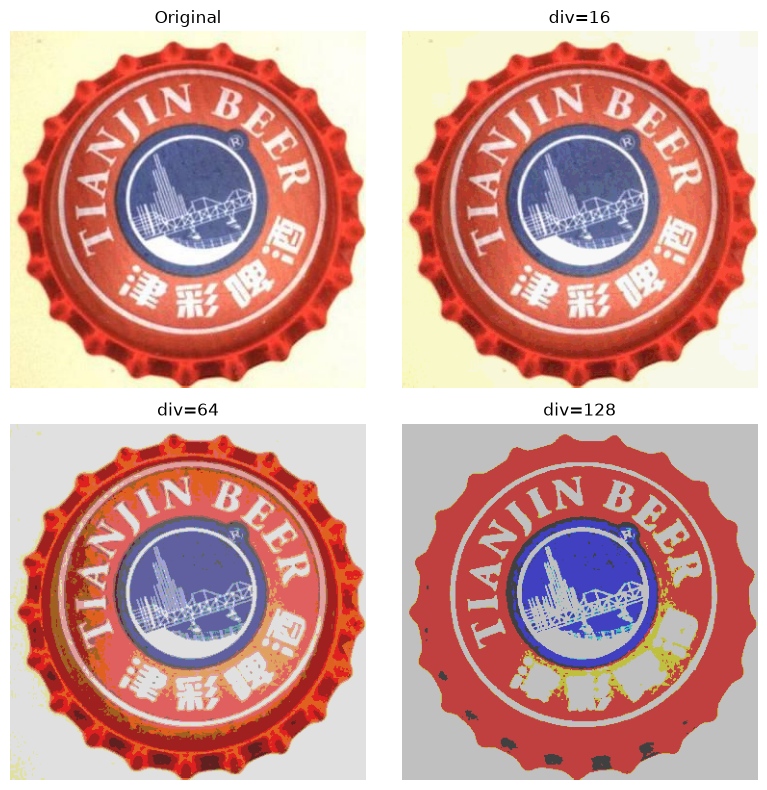

PosixPath('/Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab04/cap_quantized_64.png')

In [3]:
def color_reduce(image, div=64):
    if not 1 <= div <= 256:
        raise ValueError("div 必须在 1~256 之间")
    work = image.astype(np.uint16)
    return np.clip((work // div) * div + div // 2, 0, 255).astype(np.uint8)

quantized = {f"div={d}": color_reduce(image, d) for d in (16, 64, 128)}
show_images({"Original": image, **quantized}, cols=2, save_to=OUT / "quantization.png")
save_image(OUT / "cap_quantized_64.png", quantized["div=64"])


## 4. 调整通道并迁移到熊猫图

BGR 偏移量设为 (0, 0, 40)，表示红色通道增加 40。尝试改变三个值并记录结果。


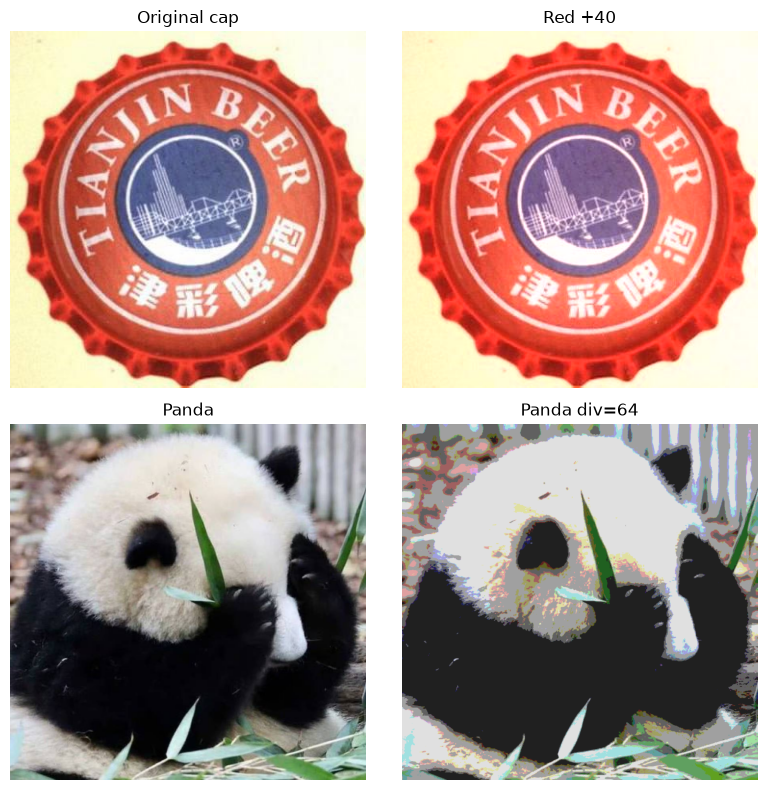

PosixPath('/Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab04/panda_quantized.png')

In [4]:
offset_bgr = np.array([0, 0, 40], dtype=np.float32)
adjusted = np.clip(image.astype(np.float32) + offset_bgr, 0, 255).astype(np.uint8)
panda = read_image(ASSETS / "user/panda.jpg")
panda_reduced = color_reduce(panda, 64)
show_images({"Original cap": image, "Red +40": adjusted,
             "Panda": panda, "Panda div=64": panda_reduced}, cols=2)
save_image(OUT / "cap_red_plus40.png", adjusted)
save_image(OUT / "panda_quantized.png", panda_reduced)


## 作业：导出对比图

先在上面的颜色调整单元格中修改 `offset_bgr`，重新运行该单元格，再运行这里。只导出通道调整结果，不需要提交量化对比图。

提交要求见 [一次实验作业](../assignments/README.md)。

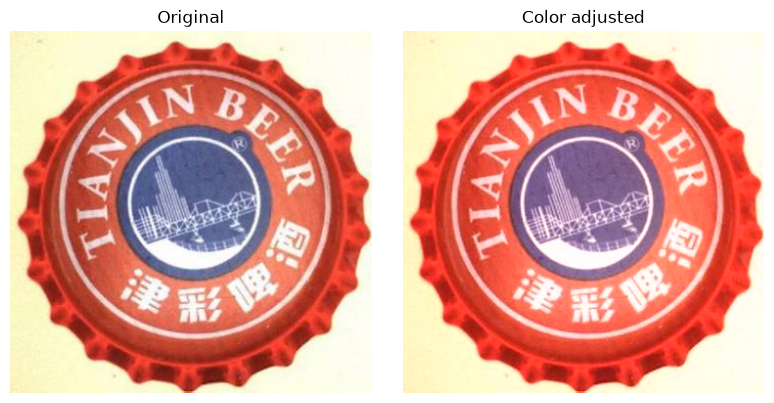

作业图片已保存到： /Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab04/02_color.png


In [5]:
show_images({"Original": image, "Color adjusted": adjusted}, cols=2,
            save_to=OUT / "02_color.png")
print("作业图片已保存到：", OUT / "02_color.png")

## 记录与思考

1. 量化后为什么会出现色块？
2. `np.uint8(250)` 加上 40 与先转换浮点数再加 40，有何区别？
3. 将 BGR 偏移改成 (40, 0, 0)，对比红色和蓝色的变化。
4. 将红色通道减小 40，比较瓶盖和熊猫图的变化。

### 我的实验记录

- 使用的素材：
- 修改的参数：
- 观察到的现象：
- 结论与原因：

> 图像和图表保存到 `outputs/lab04/`；运行本 Notebook 不会改写原始素材。
